In [ ]:
#import necessary libraries
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from matplotlib.ticker import AutoMinorLocator

import xarray as xr
import scipy

from scipy import stats
from scipy.stats import pearsonr, linregress

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd

import time
from datetime import datetime, date

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.ticker import MaxNLocator, FuncFormatter
import matplotlib.dates as mdates


import shapefile
from mpl_toolkits.axes_grid1 import make_axes_locatable
import warnings
import os

import sys
import os.path
import subprocess
import math
import csv

from netCDF4 import Dataset

#import s3fs
import copy
import json, copy
from pandas import DataFrame
from osgeo import gdal, ogr, osr

import warnings
warnings.filterwarnings("ignore")

In [ ]:
VLM_Rate = xr.open_dataset(r'D:/ThesisnetcdfFiles/Thesisfiles/VLM_Rate.nc')
VLM_Rate

<xarray.Dataset>
Dimensions:   (lon: 1441, lat: 721)
Coordinates:
  * lon       (lon) float64 0.0 0.25 0.5 0.75 1.0 ... 359.2 359.5 359.8 360.0
  * lat       (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
Data variables:
    VLM_Rate  (lat, lon) float32 ...
Attributes:
    Conventions:  CF-1.7
    title:        Interpolated Global Vertical Land Rate Models
    history:      gmt xyz2grd /home/bill/Science/XYZfiles14/vlm/GPSImaging/te...
    description:  
    GMT_version:  6.4.0 [64-bit]
    source:       Nevada Geodetic Laboratory (https://geodesy.unr.edu/vlm/VLM...
    Contact:      Sudur Bhattarai (uhkmj@kit.edu)

In [ ]:
import numpy as np

# Total number of elements in the DataArray
total_count = VLM_Rate.VLM_Rate.size  # or gravity_da.values.size

# Count of non-NaN values
non_nan_count = VLM_Rate.VLM_Rate.count().item()  # counts non-NaN values over all dims

# Count of NaN values
nan_count = np.isnan(VLM_Rate.VLM_Rate.values).sum()

print(f"Total elements: {total_count}")
print(f"Non-NaN values: {non_nan_count}")
print(f"NaN values: {nan_count}")

Total elements: 1038961
Non-NaN values: 274333
NaN values: 764628


In [ ]:
dr = VLM_Rate.VLM_Rate.values
dr

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [ ]:
df_dr = VLM_Rate.VLM_Rate.to_dataframe()
df_dr

VLM_Rate
lat   lon             
-90.0 0.00         NaN
      0.25         NaN
      0.50         NaN
      0.75         NaN
      1.00         NaN
...                ...
 90.0 359.00       NaN
      359.25       NaN
      359.50       NaN
      359.75       NaN
      360.00       NaN

[1038961 rows x 1 columns]

In [ ]:
df_dr.fillna(0, inplace=True)

In [ ]:
# Assuming df_costg is your DataFrame
df_dr_back2nc = xr.Dataset.from_dataframe(df_dr)
df_dr_back2nc.to_netcdf("VLM_nan_filled.nc")
VLM_dr= xr.open_dataset('VLM_nan_filled.nc')
VLM_dr

<xarray.Dataset>
Dimensions:   (lat: 721, lon: 1441)
Coordinates:
  * lat       (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
  * lon       (lon) float64 0.0 0.25 0.5 0.75 1.0 ... 359.2 359.5 359.8 360.0
Data variables:
    VLM_Rate  (lat, lon) float32 ...

In [ ]:
VLM_dr= xr.open_dataset('VLM_nan_filled.nc')
VLM_dr

<xarray.Dataset>
Dimensions:   (lat: 721, lon: 1441)
Coordinates:
  * lat       (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
  * lon       (lon) float64 0.0 0.25 0.5 0.75 1.0 ... 359.2 359.5 359.8 360.0
Data variables:
    VLM_Rate  (lat, lon) float32 ...

In [ ]:
dr_m = VLM_dr.VLM_Rate/1000 ##mm->m
dr_m

<xarray.DataArray 'VLM_Rate' (lat: 721, lon: 1441)>
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)
Coordinates:
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
  * lon      (lon) float64 0.0 0.25 0.5 0.75 1.0 ... 359.2 359.5 359.8 360.0

In [ ]:
dr_m.lon.values

array([0.0000e+00, 2.5000e-01, 5.0000e-01, ..., 3.5950e+02, 3.5975e+02,
       3.6000e+02])

In [ ]:
dr_m.lat.values

array([-90.  , -89.75, -89.5 , -89.25, -89.  , -88.75, -88.5 , -88.25,
       -88.  , -87.75, -87.5 , -87.25, -87.  , -86.75, -86.5 , -86.25,
       -86.  , -85.75, -85.5 , -85.25, -85.  , -84.75, -84.5 , -84.25,
       -84.  , -83.75, -83.5 , -83.25, -83.  , -82.75, -82.5 , -82.25,
       -82.  , -81.75, -81.5 , -81.25, -81.  , -80.75, -80.5 , -80.25,
       -80.  , -79.75, -79.5 , -79.25, -79.  , -78.75, -78.5 , -78.25,
       -78.  , -77.75, -77.5 , -77.25, -77.  , -76.75, -76.5 , -76.25,
       -76.  , -75.75, -75.5 , -75.25, -75.  , -74.75, -74.5 , -74.25,
       -74.  , -73.75, -73.5 , -73.25, -73.  , -72.75, -72.5 , -72.25,
       -72.  , -71.75, -71.5 , -71.25, -71.  , -70.75, -70.5 , -70.25,
       -70.  , -69.75, -69.5 , -69.25, -69.  , -68.75, -68.5 , -68.25,
       -68.  , -67.75, -67.5 , -67.25, -67.  , -66.75, -66.5 , -66.25,
       -66.  , -65.75, -65.5 , -65.25, -65.  , -64.75, -64.5 , -64.25,
       -64.  , -63.75, -63.5 , -63.25, -63.  , -62.75, -62.5 , -62.25,
      

In [ ]:
import numpy as np

# The data array
data = dr_m.values  # This is a NumPy array

# Count non-zero elements (exclude zeros)
non_zero_count = np.count_nonzero(data)

print(f"Non-zero values: {non_zero_count}")

Non-zero values: 274330


In [ ]:
total_count = data.size
zero_count = total_count - np.count_nonzero(data)

print(f"Zero values: {zero_count}")

Zero values: 764631


In [ ]:
dr_m

<xarray.DataArray 'VLM_Rate' (lat: 721, lon: 1441)>
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)
Coordinates:
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0
  * lon      (lon) float64 0.0 0.25 0.5 0.75 1.0 ... 359.2 359.5 359.8 360.0

In [ ]:
dr_m.values

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

-----
------

In [ ]:
import pandas as pd

df1 = pd.read_csv("hn_kn.txt", sep="\t")  # Change sep=" " to your file's delimiter (e.g., "," or "\t")
df1

,Degree,Average ratio
0,2,2.5683
1,3,3.6840
2,4,4.8371
3,5,6.0115
4,6,7.1856
...,...,...
250,252,502.4800
251,253,506.9500
252,254,505.9200
253,255,510.5400


In [ ]:
df1['reciprocal'] = (1 / df1['Average ratio']).round(4)
df1

,Degree,Average ratio,reciprocal
0,2,2.5683,0.3894
1,3,3.6840,0.2714
2,4,4.8371,0.2067
3,5,6.0115,0.1663
4,6,7.1856,0.1392
...,...,...,...
250,252,502.4800,0.0020
251,253,506.9500,0.0020
252,254,505.9200,0.0020
253,255,510.5400,0.0020


In [ ]:
ratio = df1[['Degree', 'reciprocal']]
ratio

,Degree,reciprocal
0,2,0.3894
1,3,0.2714
2,4,0.2067
3,5,0.1663
4,6,0.1392
...,...,...
250,252,0.0020
251,253,0.0020
252,254,0.0020
253,255,0.0020


In [ ]:
import numpy as np
from scipy.special import lpmv, factorial

def uplift_to_stokes(
    dr,            # 2D array of geometric uplift data [Y latitudes x X longitudes]
    lats,          # 1D array of latitudes in degrees (length Y)
    lons,          # 1D array of longitudes in degrees (length X)
    nmax,          # Maximum spherical harmonic degree N
    ratio_kn_hn,      # 1D array of k'_n for each degree n from 2 to nmax, length = nmax - 1
    a=6378137,     # Earth's equatorial radius in meters
    fully_normalized=True
):
    Y, X = dr.shape

    # Convert angles to radians
    lats_rad = np.deg2rad(lats)              # latitudes in radians
    lons_rad = np.deg2rad(lons)              # longitudes in radians
    colats = np.pi / 2 - lats_rad            # co-latitude θ^i in radians

    dtheta = np.abs(colats[1] - colats[0])   # spacing in theta (colatitude)
    dlam = np.abs(lons_rad[1] - lons_rad[0])# spacing in longitude

    # Initialize coefficient arrays
    dC = np.zeros((nmax + 1, nmax + 1))
    dS = np.zeros((nmax + 1, nmax + 1))

    # Loop over degrees n and orders m
    for n in range(2, nmax + 1):
        for m in range(0, n + 1):
            summation_C = 0.0
            summation_S = 0.0

            for i in range(Y):
                theta_i = colats[i]
                sin_theta_i = np.sin(theta_i)

                # Evaluate fully normalized associated Legendre polynomial P_nm(cos θ)
                Pnm = lpmv(m, n, np.cos(theta_i))
                if fully_normalized:
                    norm = np.sqrt((2*n + 1) / (4*np.pi) * factorial(n - m)/factorial(n + m))
                    Pnm *= norm

                for j in range(X):
                    lambda_j = lons_rad[j]

                    # dr at this grid point
                    dr_ij = dr[i, j]

                    cos_m_lambda = np.cos(m * lambda_j)
                    sin_m_lambda = np.sin(m * lambda_j)

                    integrand = dr_ij * Pnm * sin_theta_i * dtheta * dlam

                    summation_C += integrand * cos_m_lambda
                    summation_S += integrand * sin_m_lambda

            factor = (1 / (4 * np.pi * a)) * ratio_kn_hn[n - 2]  # ratio array starting at n=2
            dC[n, m] = factor * summation_C
            dS[n, m] = factor * summation_S

    return dC, dS

In [ ]:
nmax_total = 256
nmax_used = 96

# Initialize an array for the full range (0 to 256)
ratio_all = np.zeros(nmax_total + 1)

# Fill from dataframe
for _, row in df1.iterrows():
    deg = int(row['Degree'])
    if 0 <= deg <= nmax_total:
        ratio_all[deg] = row['reciprocal']

# Now slice the array for degrees 0 to 96 (you need degrees 2 to 96)
ratio_used = ratio_all[2:nmax_used + 1]  # slice up to 96 inclusive
ratio_used

# Call your synthesis function with nmax=96 and ratio_used
dC, dS = uplift_to_stokes(
    dr=dr_m.values,
    lats=dr_m.lat.values,
    lons=dr_m.lon.values,
    nmax=nmax_used,
    ratio_kn_hn=ratio_used,
    a=6378137
)

In [ ]:
dC, dS

(array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
                     nan,  0.00000000e+00,  0.00000000e+00],
        [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
                     nan,             nan,  0.00000000e+00],
        [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
                     nan,             nan,             nan]]),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e

In [ ]:
ratio_used

array([0.3894, 0.2714, 0.2067, 0.1663, 0.1392, 0.1197, 0.1051, 0.0937,
       0.0845, 0.077 , 0.0707, 0.0653, 0.0607, 0.0567, 0.0532, 0.0501,
       0.0473, 0.0448, 0.0426, 0.0406, 0.0387, 0.0371, 0.0355, 0.0341,
       0.0328, 0.0315, 0.0304, 0.0294, 0.0284, 0.0274, 0.0266, 0.0258,
       0.025 , 0.0243, 0.0236, 0.0229, 0.0223, 0.0217, 0.0212, 0.0207,
       0.0202, 0.0197, 0.0192, 0.0188, 0.0184, 0.018 , 0.0176, 0.0172,
       0.0168, 0.0165, 0.0162, 0.0158, 0.0155, 0.0152, 0.015 , 0.0147,
       0.0144, 0.0142, 0.0139, 0.0137, 0.0134, 0.0132, 0.013 , 0.0128,
       0.0126, 0.0124, 0.0122, 0.012 , 0.0118, 0.0116, 0.0114, 0.0112,
       0.0111, 0.0109, 0.0108, 0.0106, 0.0104, 0.0103, 0.0102, 0.01  ,
       0.0099, 0.0097, 0.0096, 0.0095, 0.0094, 0.0092, 0.0091, 0.009 ,
       0.0089, 0.0088, 0.0086, 0.0085, 0.0084, 0.0083, 0.0082])

In [ ]:
import numpy as np

dC_filled = np.nan_to_num(dC, nan=0.0)
dS_filled = np.nan_to_num(dS, nan=0.0)

In [ ]:
dC_filled, dS_filled

(array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]]),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e

In [ ]:
import pandas as pd

# Convert to DataFrame without labels (default 0..96 for rows and columns)
df_dC_filled = pd.DataFrame(dC_filled)
df_dS_filled = pd.DataFrame(dS_filled)

# Optionally, add degree and order as row/column labels:
degrees = range(dC_filled.shape[0])  # 0 to 96

df_dC_filled = pd.DataFrame(dC_filled, index=degrees, columns=degrees)
df_dS_filled = pd.DataFrame(dS_filled, index=degrees, columns=degrees)

print(df_dC_filled)
print(df_dS_filled)

              0             1             2             3             4   \
0   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
1   0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
2   4.952620e-12  3.315159e-13 -5.528820e-13  0.000000e+00  0.000000e+00   
3   1.718960e-12 -5.362080e-13 -3.268065e-13  3.027891e-13  0.000000e+00   
4   5.811921e-13 -5.679252e-13 -6.440133e-13 -8.398018e-14 -6.317966e-14   
..           ...           ...           ...           ...           ...   
92 -5.144136e-16 -5.641278e-16  1.692342e-16 -7.555235e-16  1.574992e-16   
93  2.745527e-16 -8.119114e-16  6.102669e-16 -1.676582e-15 -7.796667e-16   
94  1.725301e-15  3.102438e-16  6.036914e-16 -3.416263e-16 -4.659839e-16   
95  1.261893e-15 -4.127833e-16  8.401000e-16 -2.083286e-15 -2.819787e-16   
96  1.024917e-15  5.093202e-16  4.858360e-16 -5.410609e-16  1.928102e-16   

              5             6             7             8             9   ...  \
0   0.

In [ ]:
# Assuming df_dC_filled and df_dS_filled exist and have no NaN values
arr_dC = df_dC_filled.values
arr_dS = df_dS_filled.values

In [ ]:
import xarray as xr

degrees = range(arr_dC.shape[0])  # 0 to 96

da_dC = xr.DataArray(arr_dC, dims=['degree', 'order'], coords={'degree': degrees, 'order': degrees})
da_dS = xr.DataArray(arr_dS, dims=['degree', 'order'], coords={'degree': degrees, 'order': degrees})

print(da_dC)

print(da_dS)

<xarray.DataArray (degree: 97, order: 97)>
array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])
Coordinates:
  * degree   (degree) int32 0 1 2 3 4 5 6 7 8 9 ... 88 89 90 91 92 93 94 95 96
  * order    (order) int32 0 1 2 3 4 5 6 7 8 9 ... 87 88 89 90 91 92 93 94 95 96
<xarray.DataArray (degree: 

In [ ]:
da_dC.sizes['degree']

97

In [ ]:
dC, dS

(array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
                     nan,  0.00000000e+00,  0.00000000e+00],
        [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
                     nan,             nan,  0.00000000e+00],
        [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
                     nan,             nan,             nan]]),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e

In [ ]:
dC_filled, dS_filled

(array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]]),
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e

In [ ]:
da_dC, da_dS

(<xarray.DataArray (degree: 97, order: 97)>
 array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 4.95262025e-12,  3.31515901e-13, -5.52882020e-13, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        ...,
        [ 1.72530149e-15,  3.10243802e-16,  6.03691445e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.26189272e-15, -4.12783255e-16,  8.40100021e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.02491713e-15,  5.09320167e-16,  4.85836020e-16, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])
 Coordinates:
   * degree   (degree) int32 0 1 2 3 4 5 6 7 8 9 ... 88 89 90 91 92 93 94 95 96
   * order    (order) int32 0 1 2 3 4 5 6 7 8 9 ... 87 88 89 90 91 92 93 94 95 96,
 <xarray.

In [ ]:
da_dC.to_netcdf('dC.nc')

In [ ]:
da_dS.to_netcdf('dS.nc')

In [ ]:
ds = xr.Dataset({'dC': da_dC, 'dS': da_dS})
ds.to_netcdf('dC_dS.nc')

In [ ]:
ds_loaded = xr.open_dataset('dC_dS.nc')
ds_loaded

<xarray.Dataset>
Dimensions:  (degree: 97, order: 97)
Coordinates:
  * degree   (degree) int32 0 1 2 3 4 5 6 7 8 9 ... 88 89 90 91 92 93 94 95 96
  * order    (order) int32 0 1 2 3 4 5 6 7 8 9 ... 87 88 89 90 91 92 93 94 95 96
Data variables:
    dC       (degree, order) float64 ...
    dS       (degree, order) float64 ...

In [ ]:
import numpy as np
import xarray as xr
from scipy.special import lpmv, factorial

def compute_surface_density_signal(da_dC, da_dS, love_k_array, lats, lons,
                                   ME=5.9722e24, a=6378137.0):
    """
    Compute surface density delta sigma(θ, λ) from SH coefficients and load Love numbers.

    Parameters
    ----------
    da_dC : xarray.DataArray
        SH cosine coefficients ΔCnm, dims=('degree', 'order')
    da_dS : xarray.DataArray
        SH sine coefficients ΔSnm, dims=('degree', 'order')
    love_k_array : array-like
        Load Love numbers k_n indexed by degree n (0-based)
    lats : 1D array-like
        Latitudes in degrees (-90 to 90)
    lons : 1D array-like
        Longitudes in degrees (0 to 360)
    ME : float
        Earth's mass in kg (default WGS84)
    a : float
        Earth's mean radius in meters (default 6378137.0 m)

    Returns
    -------
    da_sigma : xarray.DataArray
        Surface density change Δσ(θ, λ) on the lat-lon grid (kg/m²)
    """

    # Convert degrees to radians
    lat_rad = np.deg2rad(lats)
    lon_rad = np.deg2rad(lons)

    # Compute colatitude θ = 90° - latitude, in radians
    theta = np.pi / 2 - lat_rad

    # Create 2D grids (latitude x longitude)
    theta_grid, lambda_grid = np.meshgrid(theta, lon_rad, indexing='ij')

    max_degree = int(da_dC.sizes['degree']) - 1

    # Initialize output grid for delta sigma
    sigma_grid = np.zeros_like(theta_grid)

    # Spherical harmonic summation from degree n=2 to N (as per formula)
    for n in range(2, max_degree + 1):
        k_n = love_k_array[n - 2]  # Love number for degree n
        factor = (2 * n + 1) / (1 + k_n)

        for m in range(0, n + 1):
            Cnm = da_dC.sel(degree=n, order=m).values.item()
            Snm = da_dS.sel(degree=n, order=m).values.item()

            # Fully normalized associated Legendre polynomial P_nm(cos θ)
            Pnm_unnorm = lpmv(m, n, np.cos(theta_grid))
            norm_factor = np.sqrt((2 * n + 1) / (4 * np.pi)
                                  * factorial(n - m) / factorial(n + m))
            Pnm = Pnm_unnorm * norm_factor

            # Longitudinal periodic functions
            cos_m_lambda = np.cos(m * lambda_grid)
            sin_m_lambda = np.sin(m * lambda_grid)

            # Spherical harmonic term contribution
            contrib = factor * Pnm * (Cnm * cos_m_lambda + Snm * sin_m_lambda)

            # Replace NaNs in contribution by zero to avoid propagation
            contrib = np.nan_to_num(contrib, nan=0.0)

            if np.isnan(contrib).any():
                print(f"NaN encountered for degree={n}, order={m}")


            # Accumulate to sigma grid
            sigma_grid += contrib

    # Multiply by constant factor ME / (4 π a^2)
    coef = ME / (4 * np.pi * a**2)
    sigma_grid *= coef

    # Wrap into xarray.DataArray
    da_sigma = xr.DataArray(
        sigma_grid,
        dims=("latitude", "longitude"),
        coords={"latitude": lats, "longitude": lons},
        name="delta_sigma",
        attrs={"units": "kg/m^2", "description": "Surface density change"}
    )

    return da_sigma

In [ ]:
love = pd.read_excel('kn2.csv.xlsx')
love

,LOVE,VarName4
0,0,-1.0000
1,1,-1.0000
2,2,-0.3054
3,3,-0.1960
4,4,-0.1337
...,...,...
1020,1020,-0.0028
1021,1021,-0.0028
1022,1022,-0.0028
1023,1023,-0.0028


In [ ]:
df1 = love.rename(columns = {"LOVE": "Degree", "VarName4": "$k_n$"})
df1

,Degree,$k_n$
0,0,-1.0000
1,1,-1.0000
2,2,-0.3054
3,3,-0.1960
4,4,-0.1337
...,...,...
1020,1020,-0.0028
1021,1021,-0.0028
1022,1022,-0.0028
1023,1023,-0.0028


In [ ]:
nmax_total = 1024
nmax_used = 96

# Initialize an array for the full range (0 to 236)
love_k_full = np.zeros(nmax_total + 1)


# Fill from dataframe
for _, row in df1.iterrows():
    deg = int(row['Degree'])
    if 0 <= deg <= nmax_total:
        love_k_full[deg] = row['$k_n$']

# Now slice the array for degrees 0 to 96 (you need degrees 2 to 96)
love_k_used = love_k_full[2:nmax_used + 1]  # slice up to 96 inclusive


da_dC_used = da_dC.sel(degree=slice(2, nmax_used))
da_dS_used = da_dS.sel(degree=slice(2, nmax_used))

lats = np.linspace(-90, 90, 720, endpoint=False)    # Example latitude grid
lons = np.linspace(0, 360, 1440, endpoint=False) # Example longitude grid


# Call your synthesis function with nmax=96 and ratio_used
# Call the function with the sliced Love numbers & SH coefficients
da_sigma = compute_surface_density_signal(
    da_dC=da_dC_used,
    da_dS=da_dS_used,
    love_k_array=love_k_used,
    lats=lats,
    lons=lons,
    ME=5.9722e24,
    a=6378137.0
)

da_sigma

<xarray.DataArray 'delta_sigma' (latitude: 720, longitude: 1440)>
array([[0.1315433 , 0.1315433 , 0.1315433 , ..., 0.1315433 , 0.1315433 ,
        0.1315433 ],
       [0.13062851, 0.1306411 , 0.13065374, ..., 0.13059103, 0.13060347,
        0.13061596],
       [0.13306582, 0.13310533, 0.13314491, ..., 0.13294776, 0.13298703,
        0.13302639],
       ...,
       [0.00714742, 0.00726842, 0.00738939, ..., 0.00678433, 0.00690537,
        0.0070264 ],
       [0.00761155, 0.00767484, 0.00773809, ..., 0.0074215 , 0.00748488,
        0.00754823],
       [0.00793538, 0.00795763, 0.00797987, ..., 0.00786858, 0.00789086,
        0.00791312]])
Coordinates:
  * latitude   (latitude) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75
  * longitude  (longitude) float64 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8
Attributes:
    units:        kg/m^2
    description:  Surface density change

In [ ]:
da_dS_used

<xarray.DataArray (degree: 95, order: 97)>
array([[ 0.00000000e+00,  6.03831386e-13, -2.84357166e-13, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  1.20069754e-12, -2.65083140e-13, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  8.37549610e-13,  3.88599410e-14, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 0.00000000e+00,  1.45958595e-15, -4.71136384e-16, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -8.28333720e-16, -8.00096182e-16, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  1.63745262e-15, -1.46195598e-15, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])
Coordinates:
  * degree   (degree) int32 2 3 4 5 6 7 8 9 10 11 ... 88 89 90 91 92 93 94 95 96
  * order    (order) int32 0 1 2 3 4 5 6 7 8 9 ... 87 88 89 90 91 92 93 94 95 96

In [ ]:
# Assuming your DataArray is named delta_sigma

# Save to NetCDF file named 'delta_sigma.nc'
da_sigma.to_netcdf('delta_sigma_full_grids.nc')

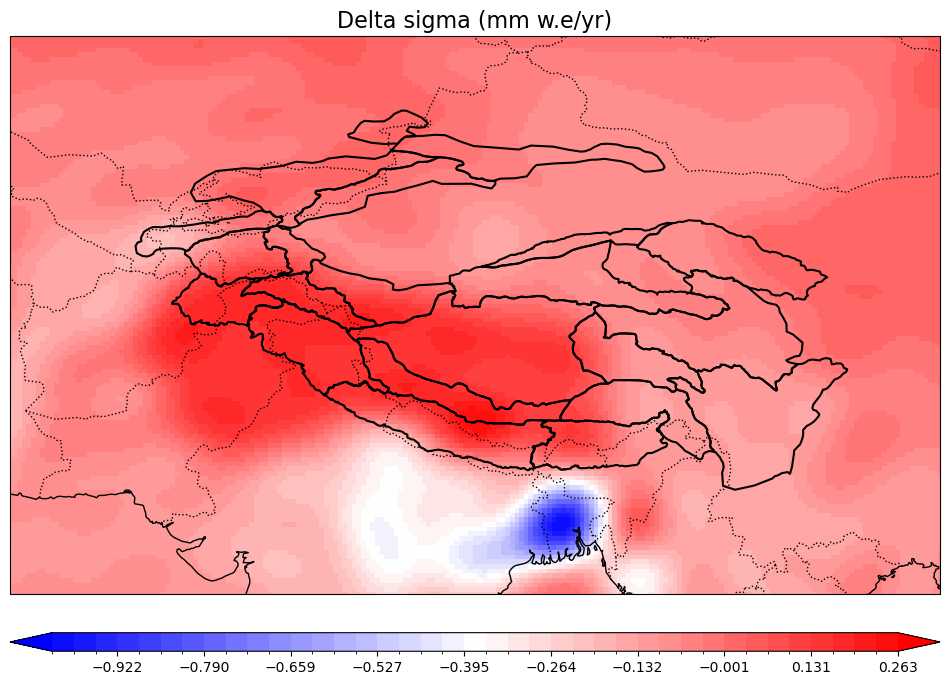

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FuncFormatter
import geopandas as gpd
import numpy as np

# --- Load your NetCDF data ---
delta_sigma = xr.open_dataarray('delta_sigma_full_grids.nc')  # your saved file

# --- Optional: Load your HMA shapefile for boundary plotting---
hma_shapefile = r'H:/Thesis/Data/HMA_shapefiles/HMA_shapefiles/TotalHMA_boundary1_22.shp'
hma_boundary = gpd.read_file(hma_shapefile).to_crs("EPSG:4326")

# --- Define region of interest (example: HMA region) ---
lon_min, lon_max = 60, 110
lat_min, lat_max = 20, 50

# --- Crop data to region of interest ---
cropped = delta_sigma.sel(latitude=slice(lat_min, lat_max), longitude=slice(lon_min, lon_max))

# --- Prepare data for plotting ---
lons = cropped['longitude'].values
lats = cropped['latitude'].values
data = cropped.values
lon2d, lat2d = np.meshgrid(lons, lats)

# Define color levels and colormap (adjust these as needed)
levels = np.linspace(np.nanmin(data), np.nanmax(data), 40)
# levels = [-0.05, -0.04, -0.03, -0.02, -0.01, 0, 0.01, 0.02, 0.03, 0.04, 0.05]
cmap = plt.get_cmap('bwr')
norm = BoundaryNorm(levels, ncolors=cmap.N, extend='both')

# --- Setup the plot ---
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot the data
im = ax.pcolormesh(
    lon2d, lat2d, data,
    cmap=cmap, norm=norm,
    # levels=levels,
    shading='auto',
    transform=ccrs.PlateCarree()
)

# Set plot extent to your region of interest
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# Add shapefile boundaries
for geom in hma_boundary.geometry:
    ax.add_geometries([geom], crs=ccrs.PlateCarree(), edgecolor='black', facecolor='none', linewidth=1.5)

# Add coastlines and borders
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=':')

# Add colorbar
cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, aspect=50)
# cbar.set_label(delta_gravity.attrs.get('units', 'Units'))

# # Add title
ax.set_title('Delta sigma (mm w.e/yr)', fontsize=16)

plt.show()